# 32 · Inverse kinematics: pseudoinverse, damped least squares, null-space, `mujoco.minimize`

In [1]:
import time, mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from mujoco import minimize
from vlacourse import add_ee_site, yaw_quat
from vlacourse.panda import pose_error

HOME = np.array([0, 0, 0, -1.571, 0, 1.571, -0.785])

def panda():
    spec = mm.get("franka_emika_panda").spec("panda")
    add_ee_site(spec)
    m = spec.compile()
    return m, mujoco.MjData(m)

def site_pose(model, data, q):
    data.qpos[:7] = q
    mujoco.mj_kinematics(model, data); mujoco.mj_comPos(model, data)
    quat = np.zeros(4); mujoco.mju_mat2Quat(quat, data.site("ee").xmat)
    return data.site("ee").xpos.copy(), quat

def jac(model, data):
    jp, jr = np.zeros((3, model.nv)), np.zeros((3, model.nv))
    mujoco.mj_jacSite(model, data, jp, jr, model.site("ee").id)
    return np.vstack([jp, jr])[:, :7]

def ik(model, data, pos, quat, q0, method="dls", lam=1e-2, null_gain=0.0, iters=300, tol=1e-4):
    q, lo, hi = q0.copy(), model.jnt_range[:7, 0], model.jnt_range[:7, 1]
    for k in range(iters):
        p, r = site_pose(model, data, q)
        e = pose_error(pos, quat, p, r)
        if np.linalg.norm(e) < tol:
            return q, k, True
        J = jac(model, data)
        if method == "pinv":
            dq = np.linalg.pinv(J) @ e
        elif method == "transpose":
            dq = 0.5 * J.T @ e
        else:
            JJt = J @ J.T + lam * np.eye(6)
            dq = J.T @ np.linalg.solve(JJt, e)
            if null_gain:
                N = np.eye(7) - np.linalg.pinv(J) @ J
                dq += null_gain * N @ (HOME - q)
        q = np.clip(q + dq, lo, hi)
    return q, iters, False

def random_target(model, data, rng):
    q = rng.uniform(model.jnt_range[:7, 0] * 0.8, model.jnt_range[:7, 1] * 0.8)
    return site_pose(model, data, q)

In [2]:
model, data = panda()
rng = np.random.default_rng(0)
targets = [random_target(model, data, rng) for _ in range(100)]
results = {}
for method in ["transpose", "pinv", "dls"]:
    t0 = time.perf_counter()
    out = [ik(model, data, p, r, HOME, method=method) for p, r in targets]
    results[method] = (np.mean([o[2] for o in out]), np.mean([o[1] for o in out]), (time.perf_counter() - t0) / len(targets) * 1000)
for k, (sr, it, ms) in results.items():
    print(f"{k:10s} success={sr:4.0%}  mean iterations={it:6.1f}  {ms:6.2f} ms/solve")

transpose  success=  2%  mean iterations= 299.4    6.55 ms/solve
pinv       success= 69%  mean iterations= 102.6    5.10 ms/solve
dls        success= 78%  mean iterations=  93.5    2.34 ms/solve


In [3]:
recovered, failed = 0, [t for t in targets if not ik(model, data, *t, HOME)[2]]
for p, r in failed:
    for _ in range(10):
        if ik(model, data, p, r, rng.uniform(model.jnt_range[:7, 0], model.jnt_range[:7, 1]))[2]:
            recovered += 1; break
print(f"DLS from HOME failed on {len(failed)} targets; random restarts recovered {recovered} of them -> {(100 - len(failed) + recovered)}% overall")

DLS from HOME failed on 22 targets; random restarts recovered 20 of them -> 98% overall


In [4]:
p, r = site_pose(model, data, HOME + np.array([0.3, 0.4, 0, -0.3, 0, 0.2, 0]))
sols = []
for s in range(6):
    q0 = rng.uniform(model.jnt_range[:7, 0] * 0.6, model.jnt_range[:7, 1] * 0.6)
    q, _, ok = ik(model, data, p, r, q0)
    if ok:
        sols.append(q)
print("same end-effector pose, different joint solutions (7-DoF redundancy):")
print(np.array(sols).round(2))

same end-effector pose, different joint solutions (7-DoF redundancy):
[[ 0.54  0.41 -0.27 -1.87  0.09  1.77 -0.86]
 [ 2.36 -1.14 -1.72 -1.8  -0.88  1.39 -0.15]
 [-0.7   0.85  1.21 -1.83 -0.64  1.57 -0.3 ]
 [-0.61  0.72  1.07 -1.84 -0.52  1.64 -0.39]
 [-0.62  0.73  1.09 -1.84 -0.53  1.64 -0.39]]


In [5]:
q_plain, _, _ = ik(model, data, p, r, HOME + 1.0 * rng.normal(size=7) * 0.3)
q_null, _, _ = ik(model, data, p, r, HOME + 1.0 * rng.normal(size=7) * 0.3, null_gain=0.1)
print("distance from home posture  plain DLS:", np.linalg.norm(q_plain - HOME).round(3), " DLS + null-space:", np.linalg.norm(q_null - HOME).round(3))
print("both reach the pose:", np.linalg.norm(site_pose(model, data, q_plain)[0] - p) < 1e-4, np.linalg.norm(site_pose(model, data, q_null)[0] - p) < 1e-4)

distance from home posture  plain DLS: 0.648  DLS + null-space: 0.629
both reach the pose: True True


In [6]:
def residual(x):
    x = np.atleast_2d(x.T).T
    out = []
    for q in x.T:
        pp, rr = site_pose(model, data, q)
        out.append(np.r_[pose_error(p, r, pp, rr), 0.005 * (q - HOME)])
    return np.array(out).T
q_ls, trace = minimize.least_squares(HOME.copy(), residual, bounds=[model.jnt_range[:7, 0], model.jnt_range[:7, 1]], verbose=0)
print(f"mujoco.minimize.least_squares: {len(trace)} iterations, pose error {np.linalg.norm(residual(q_ls)[:6]):.2e}, |q - home| = {np.linalg.norm(q_ls - HOME):.3f}")

mujoco.minimize.least_squares: 7 iterations, pose error 3.35e-05, |q - home| = 0.587


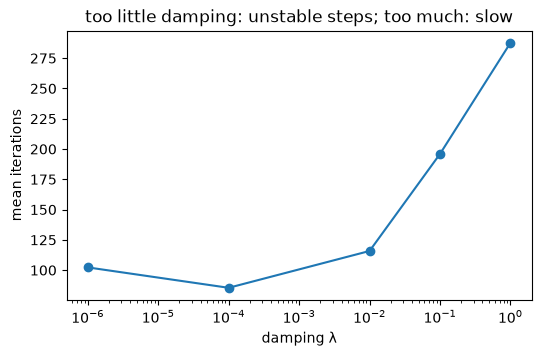

In [7]:
lams = [1e-6, 1e-4, 1e-2, 1e-1, 1.0]
iters = [np.mean([ik(model, data, pp, rr, HOME, lam=l)[1] for pp, rr in targets[:40]]) for l in lams]
plt.figure(figsize=(6, 3.5)); plt.semilogx(lams, iters, "o-"); plt.xlabel("damping λ"); plt.ylabel("mean iterations")
plt.title("too little damping: unstable steps; too much: slow"); plt.show()